# Етап 1 - Аналітика рисків здоров'я



In [108]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

In [109]:


url = "https://raw.githubusercontent.com/reinaldoq/processing-heart-disease-dataset/master/processed.cleveland.data"

columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "num"
]

df = pd.read_csv(
    url,
    header=None,
    names=columns,
    na_values="?"
)


X = df.drop(columns=["num"]).copy()
y = df["num"].copy()

print("Датасет успішно завантажено!")
print("Кількість записів:", X.shape[0])
print("Кількість ознак:", X.shape[1])

display(df.head())

Датасет успішно завантажено!
Кількість записів: 303
Кількість ознак: 13


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [110]:

print("Інформація про ознаки:")
display(X.info())

print("\nПропущені значення:")
display(X.isnull().sum())

print("\nІнформація про цільову змінну:")
display(y.info())

print("\n Унікальні значення цільової змінної:")
display(y.value_counts(dropna=False))

Інформація про ознаки:
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
dtypes: float64(13)
memory usage: 30.9 KB


None


Пропущені значення:


age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
dtype: int64


Інформація про цільову змінну:
<class 'pandas.Series'>
RangeIndex: 303 entries, 0 to 302
Series name: num
Non-Null Count  Dtype
--------------  -----
303 non-null    int64
dtypes: int64(1)
memory usage: 2.5 KB


None


 Унікальні значення цільової змінної:


num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

In [111]:

X = X.apply(pd.to_numeric, errors="coerce")


y_raw = pd.to_numeric(y, errors="coerce")


valid_rows = y_raw.notna()

X = X.loc[valid_rows].copy()
y_raw = y_raw.loc[valid_rows].copy()

print("Кількість записів після очищення:", len(X))
print("Кількість пропущених значень в ознаках:", X.isnull().sum().sum())

Кількість записів після очищення: 303
Кількість пропущених значень в ознаках: 6


In [112]:

y = (y_raw > 0).astype(int)

print("Розподіл класів:")
display(y.value_counts().sort_index())

Розподіл класів:


num
0    164
1    139
Name: count, dtype: int64

In [113]:

class_counts = y.value_counts().sort_index()


class_percentages = y.value_counts(normalize=True).sort_index() * 100

balance_table = pd.DataFrame({
    "Кількість пацієнтів": class_counts,
    "Відсоток (%)": class_percentages
})

balance_table.index = ["Низький ризик", "Високий ризик"]

display(balance_table)

,Кількість пацієнтів,Відсоток (%)
Низький ризик,164,54.125413
Високий ризик,139,45.874587


In [114]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Розмір тренувальної вибірки:", X_train.shape)
print("Розмір тестової вибірки:", X_test.shape)

print("\nРозподіл класів у Train:")
display(y_train.value_counts(normalize=True) * 100)

print("\nРозподіл класів у Test:")
display(y_test.value_counts(normalize=True) * 100)

Розмір тренувальної вибірки: (242, 13)
Розмір тестової вибірки: (61, 13)

Розподіл класів у Train:


num
0    54.132231
1    45.867769
Name: proportion, dtype: float64


Розподіл класів у Test:


num
0    54.098361
1    45.901639
Name: proportion, dtype: float64

In [115]:

imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)


scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Масштабування завершено!")
print("Train:", X_train_scaled.shape)
print("Test:", X_test_scaled.shape)

Масштабування завершено!
Train: (242, 13)
Test: (61, 13)


In [116]:

print("Середнє значення ознак у Train:")
print(np.round(X_train_scaled.mean(axis=0), 3))

print("\nСтандартне відхилення ознак у Train:")
print(np.round(X_train_scaled.std(axis=0), 3))


print("\nПідсумок підготовки даних: ")
print(f"Усього пацієнтів: {len(X)}")
print(f"Кількість ознак: {X.shape[1]}")
print(f"Train: {X_train_scaled.shape[0]} записів")
print(f"Test: {X_test_scaled.shape[0]} записів")
print(f"Пропуски після обробки: {np.isnan(X_train_scaled).sum() + np.isnan(X_test_scaled).sum()}")
print(f"Кількість класів: {y.nunique()}")

print("\nПідготовку успішно завершено!")

Середнє значення ознак у Train:
[-0.  0.  0. -0.  0. -0.  0. -0.  0.  0. -0.  0.  0.]

Стандартне відхилення ознак у Train:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Підсумок підготовки даних: 
Усього пацієнтів: 303
Кількість ознак: 13
Train: 242 записів
Test: 61 записів
Пропуски після обробки: 0
Кількість класів: 2

Підготовку успішно завершено!


# Етап 2 - MLP


In [117]:
import torch
import torch.nn as nn

In [118]:

input_size = X_train_scaled.shape[1]

print("Кількість вхідних нейронів:", input_size)

Кількість вхідних нейронів: 13


In [119]:

model = nn.Sequential(

    nn.Linear(input_size, 16),
    nn.ReLU(),


    nn.Linear(16, 8),
    nn.ReLU(),


    nn.Linear(8, 1),
    nn.Sigmoid()
)

print(" MLP успішно створено!")
print(model)

 MLP успішно створено!
Sequential(
  (0): Linear(in_features=13, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=1, bias=True)
  (5): Sigmoid()
)


In [120]:

total_params = sum(
    parameter.numel()
    for parameter in model.parameters()
)

print("Кількість параметрів моделі:", total_params)
print("Тип моделі:", type(model).__name__)


test_input = torch.tensor(
    X_train_scaled[:5],
    dtype=torch.float32
)

with torch.no_grad():
    test_output = model(test_input)

print("\nТестові виходи моделі:")
print(test_output)

print("\nРозмір вихідного тензора:", test_output.shape)

Кількість параметрів моделі: 369
Тип моделі: Sequential

Тестові виходи моделі:
tensor([[0.4109],
        [0.4310],
        [0.4065],
        [0.4267],
        [0.4171]])

Розмір вихідного тензора: torch.Size([5, 1])


# Додатково-  експорт та оцінювання моделі



In [121]:
import joblib
from pathlib import Path

In [122]:
# Створимо папку для збереження файлів
Path("artifacts").mkdir(exist_ok=True)

# Експортуємо ваги нейронної мережі
torch.save(
    model.state_dict(),
    "artifacts/healthrisk_model.pth"
)

# Експортуємо скейлер
joblib.dump(
    scaler,
    "artifacts/healthrisk_scaler.joblib"
)

# Експортуємо імпутер
joblib.dump(
    imputer,
    "artifacts/healthrisk_imputer.joblib"
)

print("Модель, скейлер  та імпутер  збережені!")

Модель, скейлер  та імпутер  збережені!


In [123]:
# Визначимо кількість вхідних ознак
input_size = X_train_scaled.shape[1]

# Створимо нову модель
loaded_model = nn.Sequential(
    nn.Linear(input_size, 16),
    nn.ReLU(),

    nn.Linear(16, 8),
    nn.ReLU(),

    nn.Linear(8, 1),
    nn.Sigmoid()
)

# Завантажимо збереженні ваги
loaded_model.load_state_dict(
    torch.load(
        "artifacts/healthrisk_model.pth",
        map_location="cpu",
        weights_only=True
    )
)

# Перейдемо у режим оцінювання
loaded_model.eval()

# Завантажимо скейлер та імпутер
loaded_scaler = joblib.load(
    "artifacts/healthrisk_scaler.joblib"
)

loaded_imputer = joblib.load(
    "artifacts/healthrisk_imputer.joblib"
)

print("Модель та обробники імпортовані!")

Модель та обробники імпортовані!


In [124]:
# Обробляємо тестові дані
X_test_imputed = loaded_imputer.transform(X_test)

X_test_ready = loaded_scaler.transform(X_test_imputed)

# Перетворюємо тензор у торчі
X_test_tensor = torch.tensor(
    X_test_ready,
    dtype=torch.float32
)

print("Тестові дані підготовлені!")
print("Розмір тензора:", X_test_tensor.shape)

Тестові дані підготовлені!
Розмір тензора: torch.Size([61, 13])


In [125]:
# Виконуємо прогнозування
with torch.no_grad():
    predictions = loaded_model(X_test_tensor)

# Отримаємо ймовірності
probabilities = predictions.numpy().flatten()

# Перетворюємо ймовірності у класи
predicted_classes = (probabilities >= 0.5).astype(int)

# Реальні значення
actual_classes = y_test.to_numpy()

print("Прогнозування завершено!")
print("Кількість прогнозів:", len(predicted_classes))

Прогнозування завершено!
Кількість прогнозів: 61


In [126]:
#таблиця
results = pd.DataFrame({
    "Actual Class": actual_classes,
    "Predicted Class": predicted_classes,
    "Probability": probabilities,
    "Correct Prediction": actual_classes == predicted_classes
})

display(results.head(15))

,Actual Class,Predicted Class,Probability,Correct Prediction
0,0,0,0.413159,True
1,0,0,0.415994,True
2,0,0,0.421480,True
3,0,0,0.444935,True
4,0,0,0.413090,True
5,0,0,0.432324,True
6,0,0,0.414994,True
7,0,0,0.397446,True
8,1,0,0.419260,False
9,0,0,0.406943,True


# Оцінюємо якість моделі

In [127]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [128]:
# Розрахунок метрика
accuracy = accuracy_score(actual_classes, predicted_classes)

precision = precision_score(
    actual_classes, predicted_classes, zero_division=0
)

recall = recall_score(
    actual_classes, predicted_classes, zero_division=0
)

f1 = f1_score(
    actual_classes, predicted_classes, zero_division=0
)

roc_auc = roc_auc_score(actual_classes, probabilities)

# Створюєсма таблиці метрика
metrics_table = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Value": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

metrics_table["Value"] = metrics_table["Value"].round(4)

display(metrics_table)

,Metric,Value
0,Accuracy,0.5410
1,Precision,0.0000
2,Recall,0.0000
3,F1-Score,0.0000
4,ROC-AUC,0.3182


In [129]:
# Виводимо детальний звіт
print("CLASSIFICATION REPORT")

print(
    classification_report(
        actual_classes,
        predicted_classes,
        target_names=["Low Risk", "High Risk"],
        zero_division=0
    )
)

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Low Risk       0.54      1.00      0.70        33
   High Risk       0.00      0.00      0.00        28

    accuracy                           0.54        61
   macro avg       0.27      0.50      0.35        61
weighted avg       0.29      0.54      0.38        61



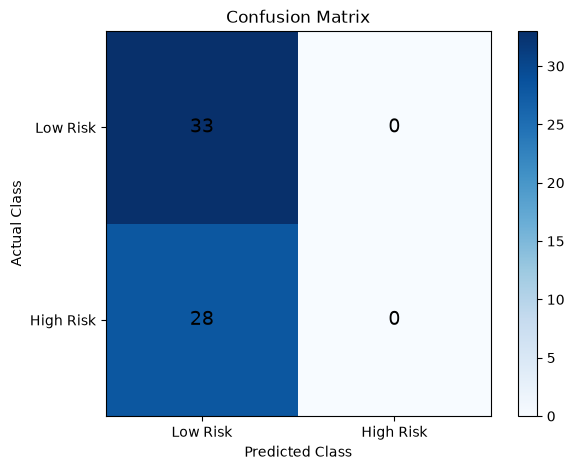

In [130]:
# Будуємо матрицю помилок
cm = confusion_matrix(actual_classes, predicted_classes)

plt.figure(figsize=(7, 5))

plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks([0, 1], ["Low Risk", "High Risk"])
plt.yticks([0, 1], ["Low Risk", "High Risk"])

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, cm[i, j],
            ha="center",
            va="center",
            color="black",
            fontsize=14
        )

plt.colorbar()
plt.show()